In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import scipy.signal as signal
from scipy.interpolate import interp1d

### SIMULACIÓN DE SISTEMAS

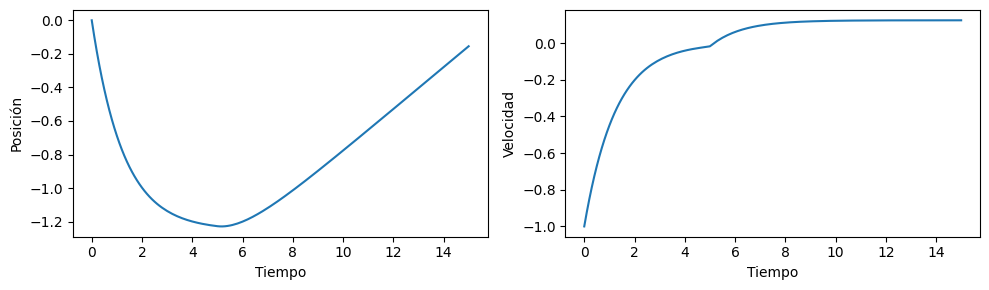

In [ ]:
# Metodo 1:
# Función que define las ecuaciones diferenciales a resolver
def sys(t, y, m, c):
    F = np.where(t >= 5, 0.1, 0)  # Fuerza aplicada después de los 5 segundos
    x1, x2 = y      # y[0] = x (posición), y[1] = dx/dt (velocidad)
    d_x1 = x2
    d_x2 = (1/m) * F - (c/m) * x2
    return [d_x1, d_x2]

# Definición de constantes
m = 1
c = 0.8
y0 = [0 , -1]  # Posición inicial = 0 m, Velocidad inicial = -1 m/s

Tm = 0.1
total_time = 15
t_span = (0, total_time)
time = np.arange(0, total_time + Tm, Tm)

# Resolver el sistema
# Solve_ivp coge los valores para la funcion: t_span (t), y0 (y), args= m,c
sol = solve_ivp(sys, t_span, y0, t_eval=time, args=(m, c))

# Gráfica de la solución
plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(sol.t, sol.y[0]) # solve devuelve la posicion y la velocidad, por eso se hace como sol.t o sol.y[0,1]
plt.xlabel('Tiempo')
plt.ylabel('Posición')

plt.subplot(1, 2, 2)
plt.plot(sol.t, sol.y[1])
plt.xlabel('Tiempo')
plt.ylabel('Velocidad')

plt.tight_layout()
plt.show()


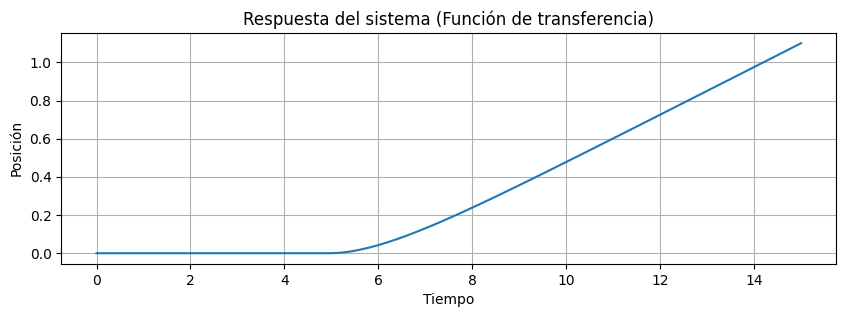

In [ ]:
# Metodo 2:
# Coeficientes del numerador y denominador de la función de transferencia
num = [1]
den = [m, c, 0]

# Entrada: fuerza escalón desde t = 5s
F = np.where(time >= 5, 0.1, 0)

# Crear sistema y simular
sys_tf = signal.TransferFunction(num, den)
t_out, y_out, _ = signal.lsim(sys_tf, F, T=time) # F (señal de entrada), T (tiempo de la simulacion que contenga en el rango de F)

# Gráfica de la solución
plt.figure(figsize=(10, 3))
plt.plot(t_out, y_out)
plt.xlabel('Tiempo')
plt.ylabel('Posición')
plt.title('Respuesta del sistema (Función de transferencia)')
plt.grid(True)
plt.show()


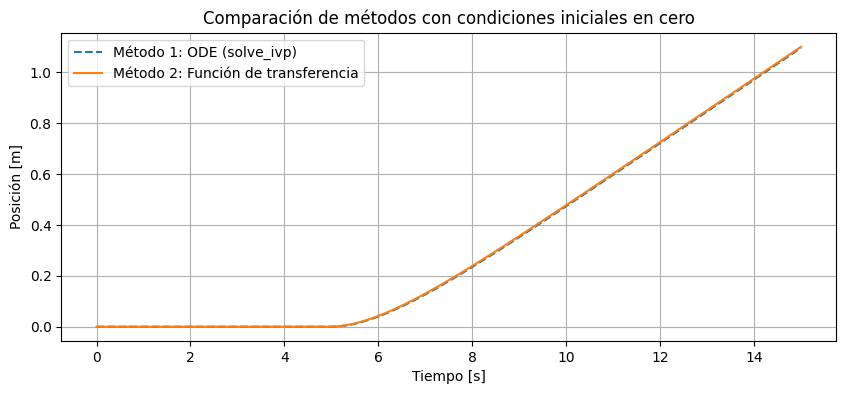

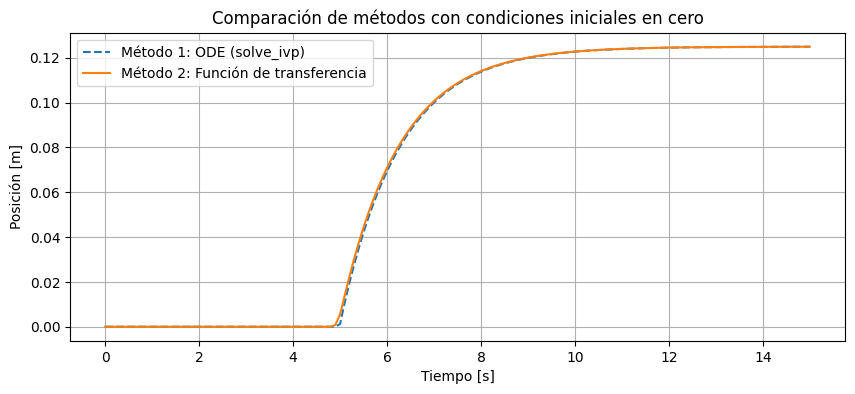

In [7]:
# Actividad:
# Condiciones iniciales ahora en cero
y0 = [0, 0]

# Resolver nuevamente con solve_ivp (método 1 con condiciones iniciales en cero)
sol_ode = solve_ivp(sys, t_span, y0, t_eval=time, args=(m, c))

# Comparación posicion en condiciones iguales a cero
plt.figure(figsize=(10, 4))
plt.plot(sol_ode.t, sol_ode.y[0], '--', label='Método 1: ODE (solve_ivp)')
plt.plot(t_out, y_out, '-', label='Método 2: Función de transferencia')
plt.xlabel('Tiempo [s]')
plt.ylabel('Posición [m]')
plt.title('Comparación de métodos con condiciones iniciales en cero')
plt.legend()
plt.grid(True)
plt.show()


# Para la velocidad
v=np.gradient(y_out,Tm)

# Comparación velocidad en condiciones iguales a cero
plt.figure(figsize=(10, 4))
plt.plot(sol_ode.t, sol_ode.y[1], '--', label='Método 1: ODE (solve_ivp)')
plt.plot(t_out, v, '-', label='Método 2: Función de transferencia')
plt.xlabel('Tiempo [s]')
plt.ylabel('Posición [m]')
plt.title('Comparación de métodos con condiciones iniciales en cero')
plt.legend()
plt.grid(True)
plt.show()


### EJERCICIO PROPUESTO

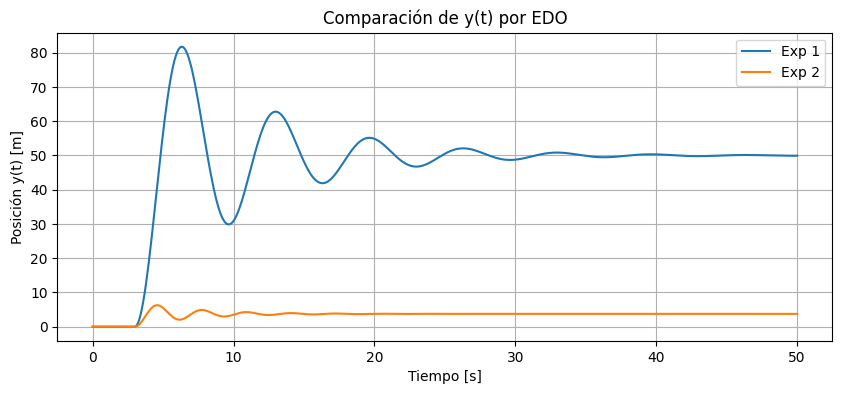

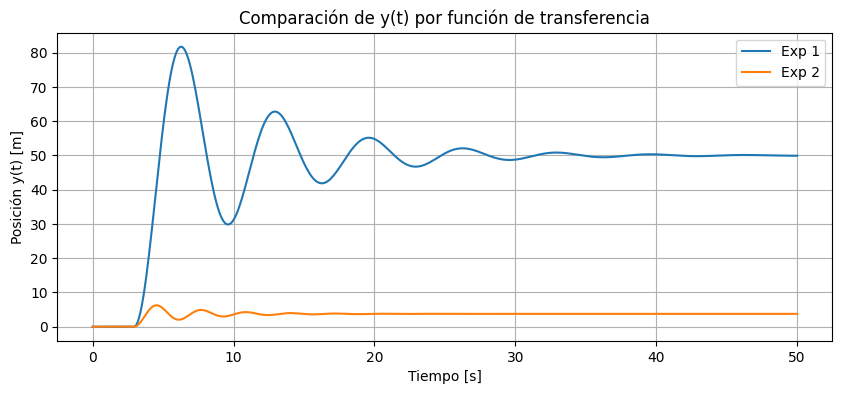

Exp 1: Máximo y(t) = 81.74 m
Exp 2: Máximo y(t) = 6.26 m


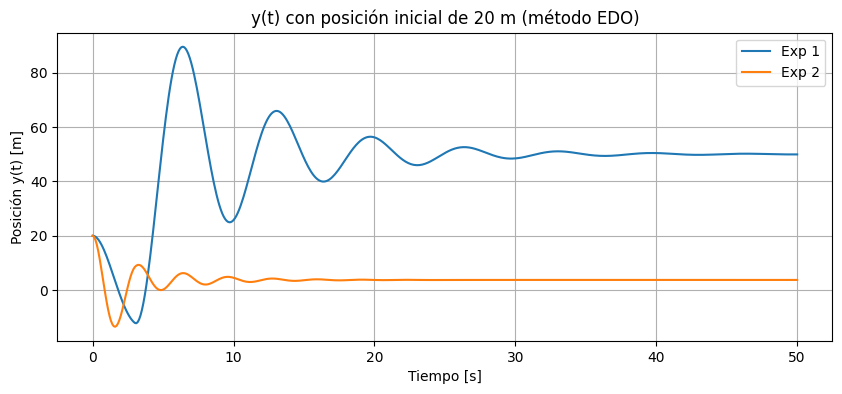

In [ ]:

# Tiempo de simulación
total_time = 50
Tm = 0.1
time = np.arange(0, total_time + Tm, Tm)

# Fuerza de entrada: 5 N a partir de t = 3 s
F = np.where(time >= 3, 5, 0)

# Parámetros por experimento
experimentos = {
    "Exp 1": {"a2": 1.1, "a1": 0.3, "a0": 1, "b0": 10},
    "Exp 2": {"a2": 1,   "a1": 0.5, "a0": 4, "b0": 3}
}


'''punto 1 - utilizando metodo 1 para los dos experimentos'''
# Punto 1
def ecuacion(t, y, a2, a1, a0, b0):
    u = 5 if t >= 3 else 0
    y1, y2 = y  # y1 = posición, y2 = velocidad
    dy1 = y2
    dy2 = (1/a2) * (b0*u - a1*y2 - a0*y1)
    return [dy1, dy2]


plt.figure(figsize=(10, 4))
for nombre, params in experimentos.items():
    y0 = [0, 0]  # posición y velocidad iniciales en 0
    sol = solve_ivp(ecuacion, [0, total_time], y0, t_eval=time,
                    args=(params["a2"], params["a1"], params["a0"], params["b0"]))
    plt.plot(sol.t, sol.y[0], label=nombre)

plt.title("Comparación de y(t) por EDO")
plt.xlabel("Tiempo [s]")
plt.ylabel("Posición y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()


'''punto 2 - Funcion de transferencia'''

plt.figure(figsize=(10, 4))

for nombre, params in experimentos.items():
    num = [params["b0"]]
    den = [params["a2"], params["a1"], params["a0"]]
    sistema = signal.TransferFunction(num, den)
    t_out, y_out, _ = signal.lsim(sistema, F, T=time)
    plt.plot(t_out, y_out, label=nombre)

plt.title("Comparación de y(t) por función de transferencia")
plt.xlabel("Tiempo [s]")
plt.ylabel("Posición y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()



'''Punto 3 - sobrepaso de 70m'''
# Verificación de máximos
for nombre, params in experimentos.items():
    num = [params["b0"]]
    den = [params["a2"], params["a1"], params["a0"]]
    sistema = signal.TransferFunction(num, den)
    _, y_out, _ = signal.lsim(sistema, F, T=time)
    y_max = np.max(y_out)
    print(f"{nombre}: Máximo y(t) = {y_max:.2f} m")



'''Punto 4 - posicion inicial en 20m'''
plt.figure(figsize=(10, 4))
for nombre, params in experimentos.items():
    y0 = [20, 0]  # posición inicial = 20 m, velocidad = 0
    sol = solve_ivp(ecuacion, [0, total_time], y0, t_eval=time,
                    args=(params["a2"], params["a1"], params["a0"], params["b0"]))
    plt.plot(sol.t, sol.y[0], label=nombre)

plt.title("y(t) con posición inicial de 20 m (método EDO)")
plt.xlabel("Tiempo [s]")
plt.ylabel("Posición y(t) [m]")
plt.legend()
plt.grid(True)
plt.show()




### TALLER SIMULACIÓN

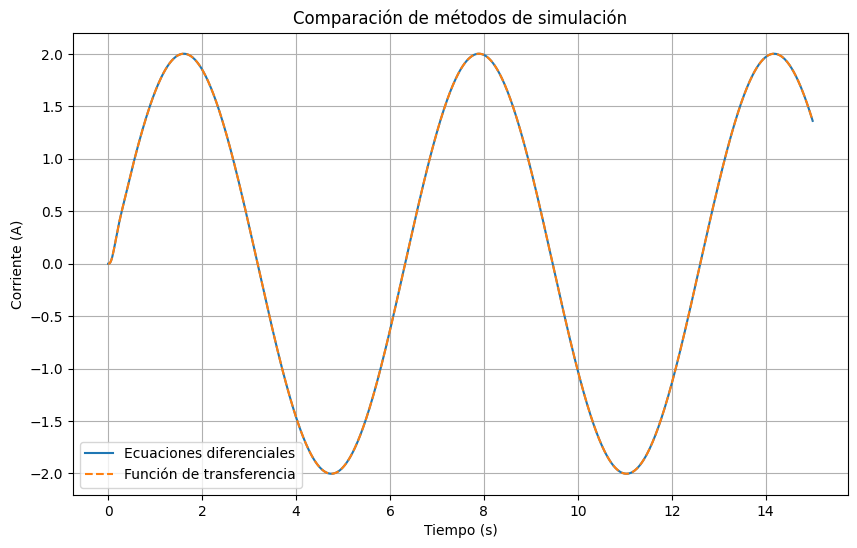

In [ ]:
'''Parte A'''

# Punto 2

# Método 1: Ecuaciones diferenciales
# Parámetros del sistema
L = 0.001  # H
R = 0.02   # Ω
C = 2      # F

def electric_system(t, I, L, R, C):
    dI1 = I[1] # Primera derivada: dI/dt
    dI2 = (np.sin(t) - R*I[1] - (1/C)*I[0]) / L  # Segunda derivada: d²I/dt² despejando de la ecuación del circuito
    return [dI1, dI2]

# Condiciones iniciales
I0 = [0, 0]  # I(0) = 0, dI/dt(0) = 0
t_span = (0, 15) # Intervalo de tiempo
t_eval = np.linspace(0, 15, 1000) # Puntos de evaluación para la solución

# Resolver el sistema
sol = solve_ivp(electric_system, t_span, I0, args=(L, R, C), t_eval=t_eval)

#--------------------------
# Método 2: Función de transferencia
numerator = [1]
denominator = [L, R, 1/C]
system = signal.TransferFunction(numerator, denominator)
t_out, y_out, _ = signal.lsim(system, U=np.sin(t_eval), T=t_eval)

# Graficar ambas soluciones
plt.figure(figsize=(10, 6))
plt.plot(sol.t, sol.y[0], label='Ecuaciones diferenciales')
plt.plot(t_out, y_out, '--', label='Función de transferencia')
plt.title('Comparación de métodos de simulación')
plt.xlabel('Tiempo (s)')
plt.ylabel('Corriente (A)')
plt.legend()
plt.grid()
plt.show()





Parámetros leídos: L=0.001 H, R=0.02 Ω, C=2.0 F


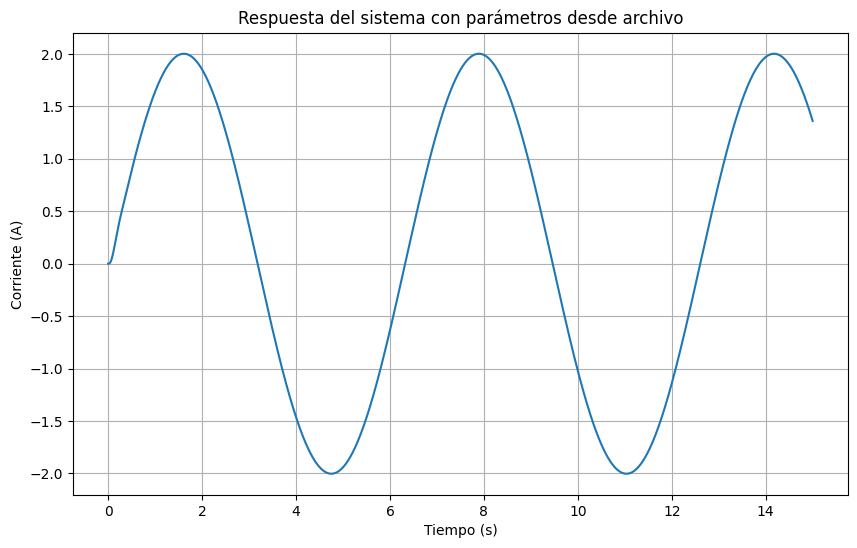

In [6]:
# Punto 3
# Leer parámetros desde archivo (formato: cada valor en una línea)
def read_parameters_simple(filename):
    with open(filename, 'r') as f:
        lines = f.readlines()
        L = float(lines[0].strip())
        R = float(lines[1].strip())
        C = float(lines[2].strip())
    return L, R, C

# Leer los parámetros
L, R, C = read_parameters_simple('parametros.txt')

print(f"Parámetros leídos: L={L} H, R={R} Ω, C={C} F")

# Resolver el sistema con los parámetros leídos
sol = solve_ivp(electric_system, t_span, I0, args=(L, R, C), t_eval=t_eval)

# Graficar
plt.figure(figsize=(10, 6))
plt.plot(sol.t, sol.y[0])
plt.title('Respuesta del sistema con parámetros desde archivo')
plt.xlabel('Tiempo (s)')
plt.ylabel('Corriente (A)')
plt.grid()
plt.show()



# Punto 4, guardar como imagen
plt.figure(figsize=(10, 6))
plt.plot(sol.t, sol.y[0])
plt.title('Respuesta del sistema eléctrico')
plt.xlabel('Tiempo (s)')
plt.ylabel('Corriente (A)')
plt.grid()
plt.savefig('respuesta_electrica.png', dpi=300)
plt.close()

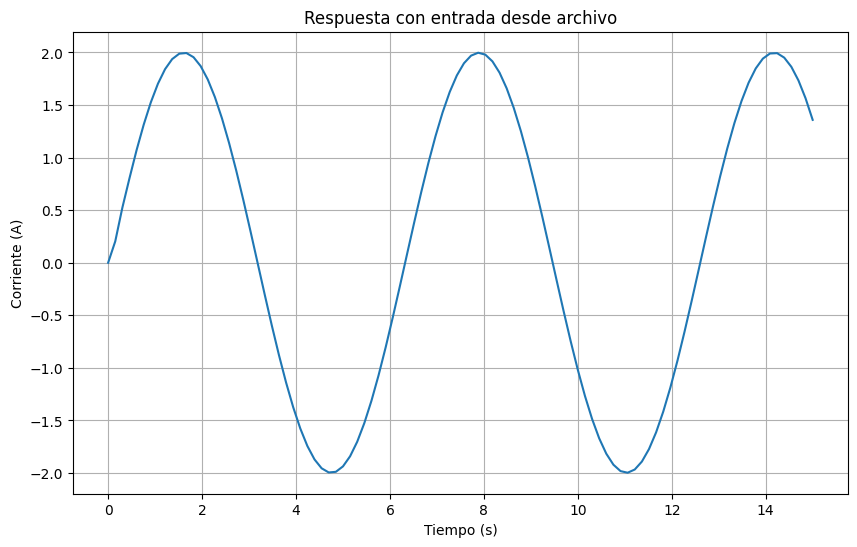

In [11]:
# Punto 5
# Generar datos de ejemplo para el archivo
t_data = np.linspace(0, 15, 100)
E_data = np.sin(t_data)
np.savetxt('Entrada.txt', np.column_stack((t_data, E_data)), fmt='%.4f')

# Leer entrada desde archivo
data = np.loadtxt("Entrada.txt")
t_txt = data[:, 0] # Tiempo
E_txt = data[:, 1] # Señal

# Crear función de interpolación
E_func = interp1d(t_txt, E_txt, fill_value="extrapolate") # Permite estimar valores de E(t) para cualquier tiempo t, incluso fuera de los datos (extrapolación)

# Modificar la función del sistema para usar entrada desde archivo
def electric_system_file(t, I, L, R, C):
    E_val = E_func(t)
    dI1 = I[1]
    dI2 = (E_val - R*I[1] - (1/C)*I[0]) / L
    return [dI1, dI2]

# Resolver
sol_file = solve_ivp(electric_system_file, (t_data[0], t_data[-1]), I0, args=(L, R, C), t_eval=t_data)

# Graficar
plt.figure(figsize=(10, 6))
plt.plot(sol_file.t, sol_file.y[0])
plt.title('Respuesta con entrada desde archivo')
plt.xlabel('Tiempo (s)')
plt.ylabel('Corriente (A)')
plt.grid()
plt.show()

In [10]:
print((t_data[0], t_data[-1]))

(0.0, 15.0)


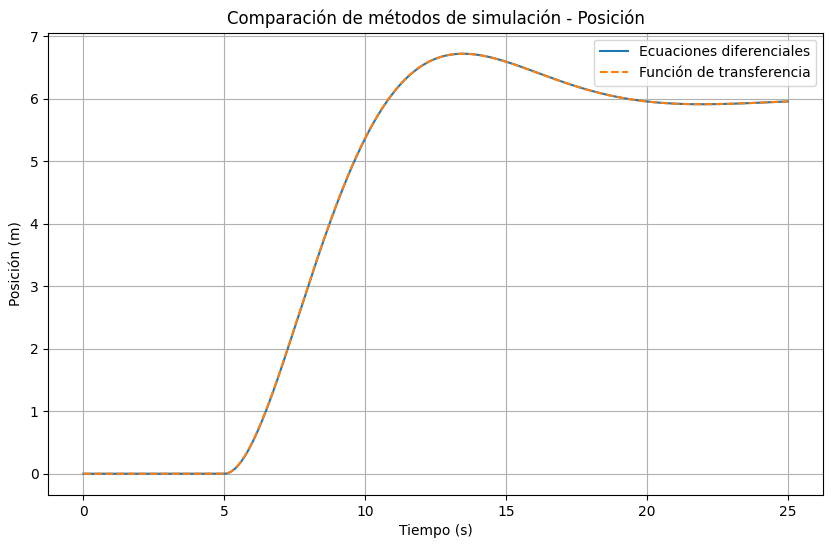

In [34]:
'''Parte B'''

# Parámetros del sistema mecánico
m = 1.0   # kg
c = 0.5   # N·s/m
k = 0.2   # N/m

# Definir la fuerza de entrada (escalón a los 5 segundos)
def fuerza_externa(t):
    return 1.2 if t >= 5 else 0

# Método 1: Ecuaciones diferenciales
def mechanical_system(t, x, m, c, k):
    F = fuerza_externa(t)
    dx1 = x[1]
    dx2 = (F - c*x[1] - k*x[0]) / m
    return [dx1, dx2]

# Condiciones iniciales
x0 = [0, 0]  # x(0) = 0, dx/dt(0) = 0
t_span_mech = (0, 25)
t_eval_mech = np.linspace(0, 25, 1000)

# Resolver el sistema
sol_mech = solve_ivp(mechanical_system, t_span_mech, x0, args=(m, c, k), t_eval=t_eval_mech)

# Método 2: Función de transferencia
numerator_mech = [1]
denominator_mech = [m, c, k]
system_mech = signal.TransferFunction(numerator_mech, denominator_mech)

# Crear señal de entrada para lsim
u_mech = np.array([fuerza_externa(t) for t in t_eval_mech])
t_out_mech, y_out_mech, _ = signal.lsim(system_mech, U=u_mech, T=t_eval_mech)

# Graficar ambas soluciones (posición)
plt.figure(figsize=(10, 6))
plt.plot(sol_mech.t, sol_mech.y[0], label='Ecuaciones diferenciales')
plt.plot(t_out_mech, y_out_mech, '--', label='Función de transferencia')
plt.title('Comparación de métodos de simulación - Posición')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición (m)')
plt.legend()
plt.grid()
plt.show()

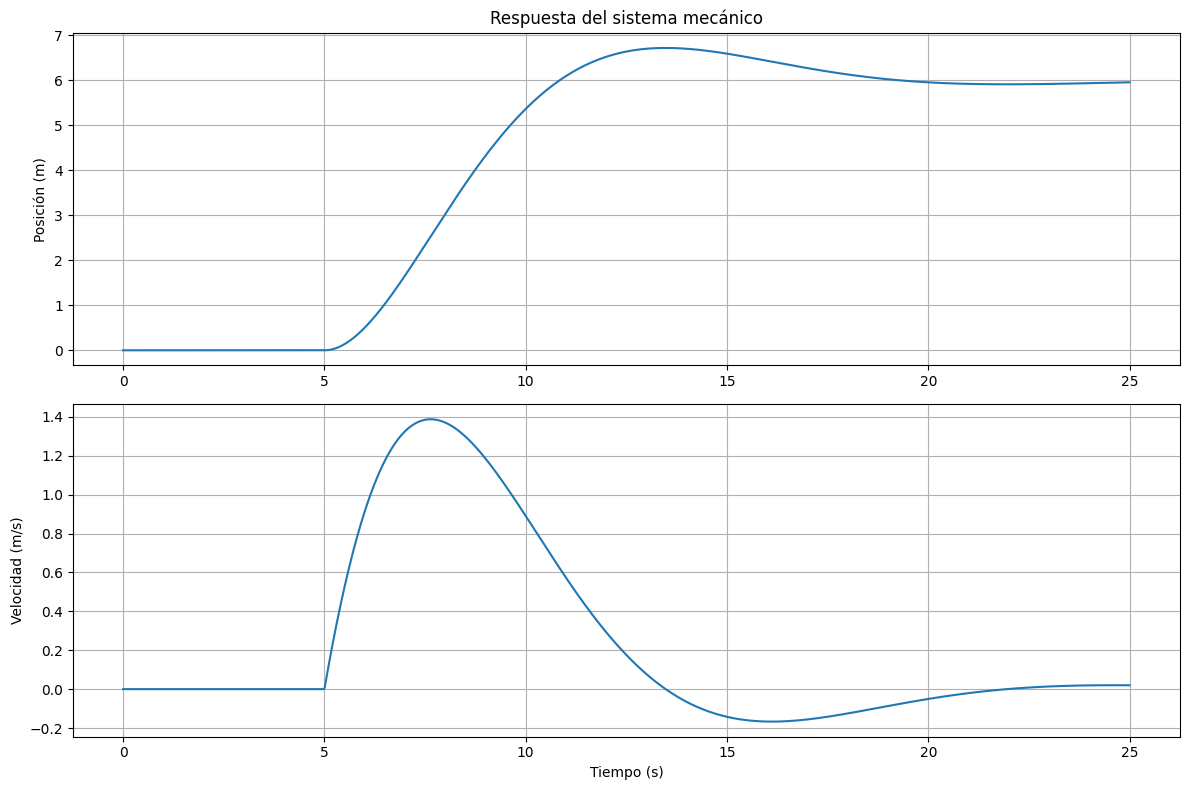

In [35]:
# Graficar posición y velocidad
plt.figure(figsize=(12, 8))

# Posición
plt.subplot(2, 1, 1)
plt.plot(sol_mech.t, sol_mech.y[0])
plt.title('Respuesta del sistema mecánico')
plt.ylabel('Posición (m)')
plt.grid()

# Velocidad
plt.subplot(2, 1, 2)
plt.plot(sol_mech.t, sol_mech.y[1])
plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad (m/s)')
plt.grid()

plt.tight_layout()
plt.show()

X(s) total:
TransferFunctionContinuous(
array([1.09090909, 5.45454545]),
array([1.        , 0.90909091]),
dt: None
)


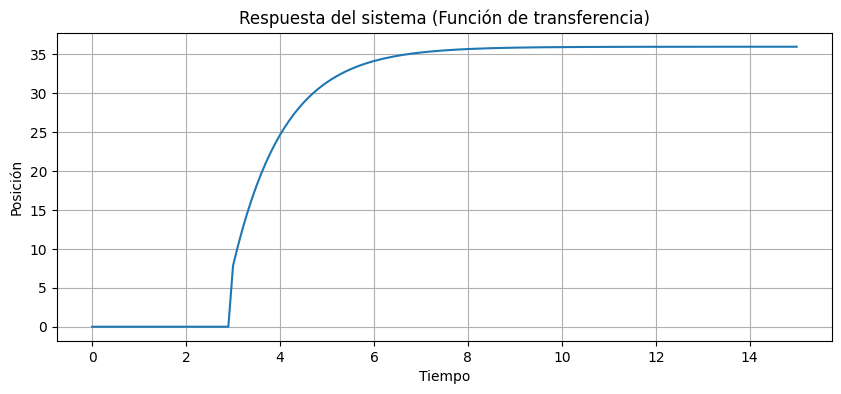

In [48]:
# Parámetros
R = 0.5     
C_S = 0.2    
C_P = 2      
F0 = 3
Fs = 6

Tm = 0.1
total_time = 15
t_span = (0, total_time)
time = np.arange(0, total_time + Tm, Tm)
F = np.where(time >= 3, Fs, 0)

# Numerador
num = [Fs, Fs / (R * C_S) - F0 / (R * C_S)]
# Denominador
den = [(1 / C_S + 1 / C_P), 1 / (R * C_S * C_P)]
X_total = signal.TransferFunction(num, den) # Función de transferencia total X(s)
print("X(s) total:")
print(X_total)


# Crear sistema y simular
t_out, y_F, _ = signal.lsim(X_total, F, T=time) # F (señal de entrada)

# Gráfica de la solución
plt.figure(figsize=(10, 4))
plt.plot(t_out, y_F)
plt.xlabel('Tiempo')
plt.ylabel('Posición')
plt.title('Respuesta del sistema (Función de transferencia)')
plt.grid(True)
plt.show()